# Vehicle Loan Default Prediction Pipeline\nThis notebook implements a cost-sensitive, calibrated stacking ensemble to predict vehicle loan defaults.

## 1. Environment Setup

In [27]:
import pandas as pd
import numpy as np
import os
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import category_encoders as ce

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, 
    fbeta_score, brier_score_loss, precision_recall_curve
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.base import clone

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

### 1.1 Compatibility Checks

In [28]:
# Handle deprecation of cv='prefit' in newer sklearn versions
try:
    from sklearn.calibration import FrozenEstimator
    USE_FROZEN = True
except ImportError:
    USE_FROZEN = False

## 2. Data Loading

In [29]:
# Load processed chunks
df_loan = pd.read_csv('/kaggle/input/datasets/karanbhatia01/input-sets/loan_details.csv')
df_customer = pd.read_csv('/kaggle/input/datasets/karanbhatia01/input-sets/customer_profile.csv')
df_bureau = pd.read_csv('/kaggle/input/datasets/karanbhatia01/input-sets/bureau_history.csv')
df_risk = pd.read_csv('/kaggle/input/datasets/karanbhatia01/input-sets/engineered_risk.csv')

### 2.1 Merging Datasets

In [30]:
# Merge into single analytical base table (ABT)
df = df_loan.merge(df_customer, on='customer_id')\
            .merge(df_bureau, on='customer_id')\
            .merge(df_risk, on='customer_id')

### 2.2 Temporal Features

In [31]:
# Extract temporal features from raw data
df_raw = pd.read_csv('/kaggle/input/datasets/sneharshinde/ltfs-av-data/train.csv')
df_raw['DisbursalDate'] = pd.to_datetime(df_raw['DisbursalDate'], format='%d-%m-%y', errors='coerce')

df['Disbursal_Quarter'] = df_raw['DisbursalDate'].dt.quarter.values
df['Disbursal_Month'] = df_raw['DisbursalDate'].dt.month.values
df['Is_End_Of_Month'] = df_raw['DisbursalDate'].dt.is_month_end.astype(int).values

### 2.3 Categorical Encoding (Basic)

In [32]:
# One-hot encode employment type
df = pd.get_dummies(df, columns=['employment_type'], drop_first=True, dtype=int)

## 3. Feature Engineering

### 3.1 Pruning

In [33]:
# Drop low-variance or highly collinear features
cols_to_drop = [
    'downpayment_ratio', 'pri_account_count', 'pri_active_accounts', 
    'pri_overdue_accounts', 'pri_current_balance', 'pri_sanctioned_amount', 
    'pri_disbursed_amount', 'pri_installment_amount', 'has_credit_history', 
    'has_passport', 'has_driving_license', 'credit_hunger_delta', 'has_voter_id'
]
df = df.drop(columns=cols_to_drop, errors='ignore')

### 3.2 Interaction Features

In [34]:
# Engineer interaction features based on financial logic
df['ltv_x_bureau'] = df['ltv'] * df['bureau_score']
df['installment_burden'] = df['total_installment_amount'] / (df['disbursed_amount'] + 1)
df['overdue_per_account'] = df['total_overdue_accounts'] / (df['total_account_count'] + 1)
df['balance_to_sanctioned'] = df['total_current_balance'] / (df['total_sanctioned_amount'] + 1)
df['inquiry_per_month'] = df['inquiry_count'] / (df['credit_history_months'] + 1)
df['age_x_credit'] = df['age_at_disbursal'] * df['credit_history_months']
df['new_acct_velocity'] = df['new_accounts_6m'] / (df['total_account_count'] + 1)

## 4. Preprocessing Configuration

### 4.1 Define Target & Features

In [35]:
X = df.drop(columns=['loan_default', 'asset_cost', 'customer_id'], errors='ignore')
y = df['loan_default']

### 4.2 Format High-Cardinality Categoricals

In [36]:
cat_cols = ['branch_id', 'supplier_id', 'manufacturer_id', 'pincode_id', 'state_id', 'employee_id']
for c in cat_cols:
    if c in X.columns:
        X[c] = X[c].fillna(-1).astype(int).astype(str)

### 4.3 Log-Transform Skewed Features

In [37]:
# Log-transform highly skewed currency features to pull in long tails
skewed_cols = ['disbursed_amount', 'total_current_balance', 'total_sanctioned_amount']
for c in skewed_cols:
    if c in X.columns:
        X[c] = np.log1p(np.clip(X[c], 0, None))

### 4.4 Define Monotonic Constraints

In [38]:
# Define monotonic constraints to force logical splits in trees
mono_constraints = {
    'ltv': 1,              
    'bureau_score': -1,   
    'total_active_accounts': -1,
    'overdue_ratio': 1,   
    'credit_utilization': 1,
    'age_at_disbursal': -1,
    'inquiry_count': 1
}

### 4.5 Class Imbalance Baseline

In [39]:
# Calculate baseline weight for class imbalance
base_scale_pos_weight = (len(y) - sum(y)) / sum(y)
print(f"Base scale_pos_weight: {base_scale_pos_weight:.2f}")

Base scale_pos_weight: 3.61


## 5. Model Initialization\nDefining the base models. Note: Built-in balancing parameters are removed because we will manually supply dynamic sample weights during training.

In [40]:
models = {
    'XGBoost': XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        monotone_constraints=mono_constraints, subsample=0.8, colsample_bytree=0.8,
        n_jobs=-1, eval_metric='auc', random_state=42
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, verbose=-1, random_state=42
    ),
    'CatBoost': CatBoostClassifier(
        iterations=300, depth=5, learning_rate=0.05,
        eval_metric='AUC', random_seed=42, verbose=0
    )
}

## 6. Helper Functions

In [41]:
def sweep_f2(y_true, y_pred_proba):
    """Finds the optimal probability threshold to maximize F2 score."""
    precision, recall, thresholds = precision_recall_curve(y_true, y_pred_proba)
    denominator = 4 * precision + recall
    f2_scores = np.divide(5 * precision * recall, denominator, out=np.zeros_like(denominator), where=denominator!=0)
    best_idx = np.argmax(f2_scores)
    
    best_f2 = f2_scores[best_idx]
    best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 1.0
    return best_f2, best_thresh

## 7. Cross-Validation Setup

In [42]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = {name: np.zeros(len(X)) for name in models}

### 7.1 Execution Loop\nExecutes a 5-fold Stratified CV. Inside each fold:\n1. Nests a calibration split (80/20).\n2. Applies Target Encoding without leakage.\n3. Computes normalized, cost-sensitive sample weights based on loan size.\n4. Trains models and fits an Isotonic calibrator.

In [43]:
print("Initiating 5-Fold Training & Calibration...")

for fold_idx, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    print(f"\n--- Fold {fold_idx + 1}/5 ---")
    
    X_train, y_train = X.iloc[train_idx].copy(), y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx].copy(), y.iloc[val_idx]
    
    # 1. Nested split for calibration (stratified to maintain default ratio)
    X_t, X_cal, y_t, y_cal = train_test_split(
        X_train, y_train, test_size=0.20, stratify=y_train, random_state=42
    )
    
    # 2. Target encoding (fit on training subset only)
    te = ce.TargetEncoder(cols=cat_cols, smoothing=10, min_samples_leaf=20)
    X_t = te.fit_transform(X_t, y_t).fillna(0)
    X_cal = te.transform(X_cal).fillna(0)
    X_val = te.transform(X_val).fillna(0)
    
    # 3. Compute normalized sample weights (penalize missing large loans)
    mean_disbursed = np.expm1(X_t['disbursed_amount']).mean()
    fin_penalty = np.clip(np.expm1(X_t['disbursed_amount']) / mean_disbursed, 0.5, 3.0)
    base_weight = np.where(y_t == 1, base_scale_pos_weight, 1.0)
    
    sample_weight_t = base_weight * fin_penalty
    sample_weight_t = sample_weight_t / sample_weight_t.mean() 
    
    for model_name, model_template in models.items():
        model = clone(model_template)
        
        try:
            # 4. Train with weights
            model.fit(X_t, y_t, sample_weight=sample_weight_t)
            
            # 5. Calibrate without weights
            if USE_FROZEN:
                calibrator = CalibratedClassifierCV(FrozenEstimator(model), method='isotonic')
            else:
                calibrator = CalibratedClassifierCV(model, cv='prefit', method='isotonic')
            
            calibrator.fit(X_cal, y_cal)
            
            # 6. Predict
            preds = calibrator.predict_proba(X_val)[:, 1]
            oof_preds[model_name][val_idx] = preds
            
            # Metrics
            f_pr = average_precision_score(y_val, preds)
            f_f2, f_thresh = sweep_f2(y_val, preds)
            print(f"  {model_name.ljust(16)} | PR: {f_pr:.3f} | F2: {f_f2:.3f} (@{f_thresh:.2f})")
            
        except Exception as e:
            oof_preds[model_name][val_idx] = 0.5
            print(f"  {model_name} failed: {str(e)[:50]}")

Initiating 5-Fold Training & Calibration...

--- Fold 1/5 ---
  XGBoost          | PR: 0.328 | F2: 0.593 (@0.14)
  LightGBM         | PR: 0.329 | F2: 0.592 (@0.13)
  CatBoost         | PR: 0.326 | F2: 0.592 (@0.12)

--- Fold 2/5 ---
  XGBoost          | PR: 0.331 | F2: 0.591 (@0.12)
  LightGBM         | PR: 0.328 | F2: 0.592 (@0.12)
  CatBoost         | PR: 0.329 | F2: 0.592 (@0.13)

--- Fold 3/5 ---
  XGBoost          | PR: 0.330 | F2: 0.591 (@0.13)
  LightGBM         | PR: 0.330 | F2: 0.590 (@0.10)
  CatBoost         | PR: 0.327 | F2: 0.591 (@0.12)

--- Fold 4/5 ---
  XGBoost          | PR: 0.336 | F2: 0.594 (@0.13)
  LightGBM         | PR: 0.335 | F2: 0.593 (@0.13)
  CatBoost         | PR: 0.336 | F2: 0.594 (@0.13)

--- Fold 5/5 ---
  XGBoost          | PR: 0.336 | F2: 0.590 (@0.12)
  LightGBM         | PR: 0.337 | F2: 0.590 (@0.13)
  CatBoost         | PR: 0.335 | F2: 0.589 (@0.13)


## 8. Base Model Evaluation

In [44]:
oof_scores = {}
print("Base Models (OOF Performance):")

for name in models:
    try:
        preds = oof_preds[name]
        r_roc = roc_auc_score(y, preds)
        r_pr = average_precision_score(y, preds)
        r_f2, r_thresh = sweep_f2(y, preds)
        r_brier = brier_score_loss(y, preds)
        oof_scores[name] = {'ROC': r_roc, 'PR': r_pr, 'F2': r_f2, 'F2_Thresh': r_thresh, 'Brier': r_brier}
        print(f"{name.ljust(18)} PR-AUC: {r_pr:.4f} | F2: {r_f2:.4f} (@{r_thresh:.2f}) | Brier: {r_brier:.4f}")
    except:
        pass

Base Models (OOF Performance):
XGBoost            PR-AUC: 0.3367 | F2: 0.5915 (@0.12) | Brier: 0.1610
LightGBM           PR-AUC: 0.3364 | F2: 0.5912 (@0.13) | Brier: 0.1610
CatBoost           PR-AUC: 0.3347 | F2: 0.5914 (@0.13) | Brier: 0.1612


### 8.1 Select Top Models

In [45]:
# Select Top 3 for Stacking
leaderboard = sorted(oof_scores.items(), key=lambda x: x[1]['PR'], reverse=True)
top3_names = [name for name, _ in leaderboard[:3]]
print(f"Selected for Stacking: {top3_names}")

Selected for Stacking: ['XGBoost', 'LightGBM', 'CatBoost']


## 9. Base Model Calibration Curve

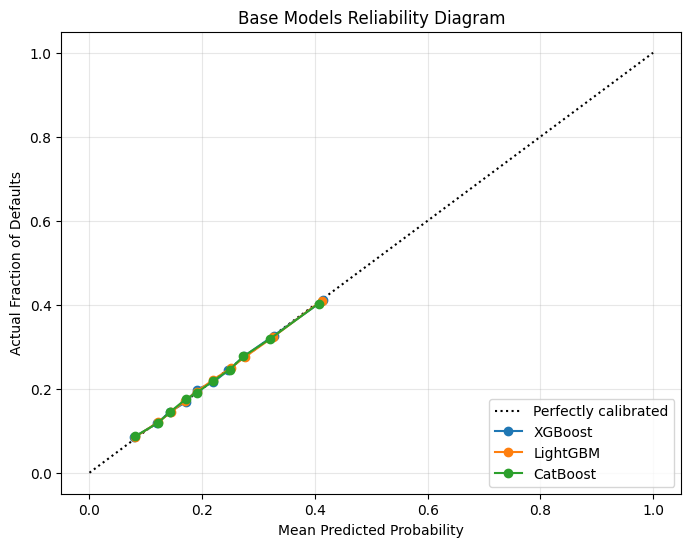

In [46]:
os.makedirs('../charts', exist_ok=True)

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")

for name in top3_names:
    prob_true, prob_pred = calibration_curve(y, oof_preds[name], n_bins=10, strategy='quantile')
    plt.plot(prob_pred, prob_true, marker='o', label=name)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Fraction of Defaults")
plt.title("Base Models Reliability Diagram")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.savefig('../charts/12a_base_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Meta-Model Stacking\nBlending the calibrated probabilities using Logistic Regression to find the optimal ensemble weights.

In [47]:
meta_X = np.column_stack([oof_preds[name] for name in top3_names])
meta_model = LogisticRegression(max_iter=1000, random_state=42)
meta_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

meta_preds = np.zeros(len(X))
for train_idx, val_idx in meta_cv.split(meta_X, y):
    meta_model.fit(meta_X[train_idx], y.iloc[train_idx])
    meta_preds[val_idx] = meta_model.predict_proba(meta_X[val_idx])[:, 1]

### 10.1 Meta-Model Evaluation

In [48]:
s_roc = roc_auc_score(y, meta_preds)
s_pr = average_precision_score(y, meta_preds)
s_f2, s_thresh = sweep_f2(y, meta_preds)
s_brier = brier_score_loss(y, meta_preds)

print("Stacked Meta-Model Performance:")
print(f"PR-AUC:   {s_pr:.4f}")
print(f"F2-Score: {s_f2:.4f} (@{s_thresh:.2f})")
print(f"Brier:    {s_brier:.4f}")
print(f"ROC-AUC:  {s_roc:.4f}")

Stacked Meta-Model Performance:
PR-AUC:   0.3390
F2-Score: 0.5920 (@0.13)
Brier:    0.1611
ROC-AUC:  0.6566


### 10.2 Meta-Model Weights

In [49]:
# Train final meta-model on all data to inspect weights
meta_model.fit(meta_X, y)
print("Ensemble Weights:")
for name, coef in zip(top3_names, meta_model.coef_[0]):
    print(f"  {name}: {coef:.4f}")

Ensemble Weights:
  XGBoost: 1.9114
  LightGBM: 1.8968
  CatBoost: 1.8434


## 11. Meta-Model Calibration Curve

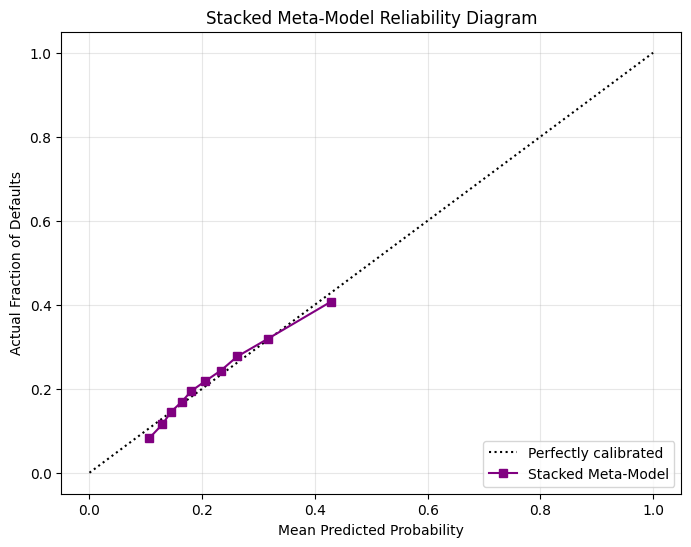

In [50]:
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")
prob_true, prob_pred = calibration_curve(y, meta_preds, n_bins=10, strategy='quantile')
plt.plot(prob_pred, prob_true, marker='s', color='purple', label='Stacked Meta-Model')

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Fraction of Defaults")
plt.title("Stacked Meta-Model Reliability Diagram")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.savefig('../charts/12b_meta_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

---\n# Phase 2: Hyperparameter Tuning\nTuning the top 3 base models using RandomizedSearchCV with stratified cross-validation.

## 12. Tuning Setup

In [51]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import pickle

# Prepare a single train/calibration/validation split for tuning
# Using the same nested architecture as the OOF loop
X_tune, X_holdout, y_tune, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Target encode (fit on tune set only)
te_tune = ce.TargetEncoder(cols=cat_cols, smoothing=10, min_samples_leaf=20)
X_tune_enc = te_tune.fit_transform(X_tune, y_tune).fillna(0)
X_holdout_enc = te_tune.transform(X_holdout).fillna(0)

# Compute sample weights for tuning set
mean_d = np.expm1(X_tune_enc['disbursed_amount']).mean()
fp = np.clip(np.expm1(X_tune_enc['disbursed_amount']) / mean_d, 0.5, 3.0)
bw = np.where(y_tune == 1, base_scale_pos_weight, 1.0)
sw_tune = bw * fp
sw_tune = sw_tune / sw_tune.mean()

tune_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print(f"Tuning set: {len(X_tune_enc)} rows | Holdout: {len(X_holdout_enc)} rows")

Tuning set: 186523 rows | Holdout: 46631 rows


### 12.1 Search Spaces

In [54]:
search_spaces = {
    'XGBoost': {
        'model': XGBClassifier(
            monotone_constraints=mono_constraints,
            eval_metric='auc', random_state=42
        ),
        'params': {
            'n_estimators': randint(200, 600),
            'max_depth': randint(3, 8),
            'learning_rate': uniform(0.01, 0.15),
            'subsample': uniform(0.6, 0.4),
            'colsample_bytree': uniform(0.5, 0.5),
            'min_child_weight': randint(1, 10),
            'reg_alpha': uniform(0, 1.0),
            'reg_lambda': uniform(0.5, 2.0),
            'gamma': uniform(0, 0.5),
        }
    },
    'LightGBM': {
        'model': LGBMClassifier(verbose=-1, random_state=42),
        'params': {
            'n_estimators': randint(200, 600),
            'max_depth': randint(3, 8),
            'learning_rate': uniform(0.01, 0.15),
            'subsample': uniform(0.6, 0.4),
            'colsample_bytree': uniform(0.5, 0.5),
            'num_leaves': randint(20, 80),
            'min_child_samples': randint(10, 100),
            'reg_alpha': uniform(0, 1.0),
            'reg_lambda': uniform(0.5, 2.0),
        }
    },
    'CatBoost': {
        'model': CatBoostClassifier(eval_metric='AUC', random_seed=42, verbose=0),
        'params': {
            'iterations': randint(200, 600),
            'depth': randint(3, 8),
            'learning_rate': uniform(0.01, 0.15),
            'l2_leaf_reg': uniform(1, 9),
            'bagging_temperature': uniform(0, 1),
            'random_strength': uniform(0, 1),
        }
    }
}

### 12.2 Run Tuning

In [55]:
tuned_results = {}

for name in top3_names:
    if name not in search_spaces:
        print(f"Skipping {name} (no search space defined)")
        continue
    
    config = search_spaces[name]
    print(f"\nTuning {name}...")
    start = time.time()
    
    search = RandomizedSearchCV(
        estimator=config['model'],
        param_distributions=config['params'],
        n_iter=30,
        scoring='average_precision',
        cv=tune_cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
    )
    
    search.fit(X_tune_enc, y_tune, sample_weight=sw_tune)
    
    elapsed = round(time.time() - start, 1)
    
    # Evaluate on holdout
    holdout_preds = search.best_estimator_.predict_proba(X_holdout_enc)[:, 1]
    h_pr = average_precision_score(y_holdout, holdout_preds)
    h_roc = roc_auc_score(y_holdout, holdout_preds)
    h_f2, h_thresh = sweep_f2(y_holdout, holdout_preds)
    
    tuned_results[name] = {
        'best_params': search.best_params_,
        'cv_pr_auc': search.best_score_,
        'holdout_pr_auc': h_pr,
        'holdout_roc_auc': h_roc,
        'holdout_f2': h_f2,
        'holdout_f2_thresh': h_thresh,
        'estimator': search.best_estimator_,
    }
    
    print(f"  CV PR-AUC:      {search.best_score_:.4f}")
    print(f"  Holdout PR-AUC: {h_pr:.4f}")
    print(f"  Holdout ROC:    {h_roc:.4f}")
    print(f"  Holdout F2:     {h_f2:.4f} (@{h_thresh:.2f})")
    print(f"  Time: {elapsed}s")


Tuning XGBoost...
  CV PR-AUC:      0.4071
  Holdout PR-AUC: 0.3465
  Holdout ROC:    0.6617
  Holdout F2:     0.5951 (@0.23)
  Time: 305.9s

Tuning LightGBM...
  CV PR-AUC:      0.4067
  Holdout PR-AUC: 0.3457
  Holdout ROC:    0.6614
  Holdout F2:     0.5949 (@0.24)
  Time: 575.2s

Tuning CatBoost...
  CV PR-AUC:      0.4065
  Holdout PR-AUC: 0.3439
  Holdout ROC:    0.6593
  Holdout F2:     0.5934 (@0.24)
  Time: 650.7s


### 12.3 Best Parameters

In [56]:
for name, result in tuned_results.items():
    print(f"\n{name} Best Parameters:")
    for param, value in sorted(result['best_params'].items()):
        if isinstance(value, float):
            print(f"  {param}: {value:.4f}")
        else:
            print(f"  {param}: {value}")


XGBoost Best Parameters:
  colsample_bytree: 0.5527
  gamma: 0.2283
  learning_rate: 0.0428
  max_depth: 6
  min_child_weight: 7
  n_estimators: 547
  reg_alpha: 0.3563
  reg_lambda: 2.3137
  subsample: 0.7089

LightGBM Best Parameters:
  colsample_bytree: 0.5324
  learning_rate: 0.0481
  max_depth: 6
  min_child_samples: 48
  n_estimators: 585
  num_leaves: 22
  reg_alpha: 0.3009
  reg_lambda: 1.0697
  subsample: 0.6148

CatBoost Best Parameters:
  bagging_temperature: 0.2441
  depth: 5
  iterations: 573
  l2_leaf_reg: 2.9689
  learning_rate: 0.0937
  random_strength: 0.4038


## 13. Tuned Model Comparison

In [57]:
print("Tuned Model Comparison (Holdout Set):\n")
print(f"{'Model'.ljust(18)} {'PR-AUC'.ljust(10)} {'F2'.ljust(12)} {'ROC-AUC'.ljust(10)}")
print("-" * 52)

for name, result in sorted(tuned_results.items(), key=lambda x: x[1]['holdout_pr_auc'], reverse=True):
    pr = result['holdout_pr_auc']
    f2 = result['holdout_f2']
    ft = result['holdout_f2_thresh']
    roc = result['holdout_roc_auc']
    print(f"{name.ljust(18)} {pr:.4f}     {f2:.4f} (@{ft:.2f}) {roc:.4f}")

# Identify the single best model
best_name = max(tuned_results, key=lambda k: tuned_results[k]['holdout_pr_auc'])
print(f"\nBest model: {best_name}")

Tuned Model Comparison (Holdout Set):

Model              PR-AUC     F2           ROC-AUC   
----------------------------------------------------
XGBoost            0.3465     0.5951 (@0.23) 0.6617
LightGBM           0.3457     0.5949 (@0.24) 0.6614
CatBoost           0.3439     0.5934 (@0.24) 0.6593

Best model: XGBoost


## 14. Build Final Production Pipeline\nRetrain the best tuned model on the full dataset and save with its TargetEncoder and Isotonic calibrator.

### 14.1 Final Train/Calibration Split

In [58]:
# Split full data for final training + calibration
X_final_train, X_final_cal, y_final_train, y_final_cal = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# Target encode
te_final = ce.TargetEncoder(cols=cat_cols, smoothing=10, min_samples_leaf=20)
X_ft_enc = te_final.fit_transform(X_final_train, y_final_train).fillna(0)
X_fc_enc = te_final.transform(X_final_cal).fillna(0)

# Sample weights for final training
mean_d_f = np.expm1(X_ft_enc['disbursed_amount']).mean()
fp_f = np.clip(np.expm1(X_ft_enc['disbursed_amount']) / mean_d_f, 0.5, 3.0)
bw_f = np.where(y_final_train == 1, base_scale_pos_weight, 1.0)
sw_final = bw_f * fp_f
sw_final = sw_final / sw_final.mean()

print(f"Final train: {len(X_ft_enc)} | Calibration: {len(X_fc_enc)}")

Final train: 198180 | Calibration: 34974


### 14.2 Train Best Model

In [59]:
# Reconstruct the best model with tuned params
best_params = tuned_results[best_name]['best_params']

if best_name == 'XGBoost':
    final_model = XGBClassifier(
        **best_params,
        monotone_constraints=mono_constraints,
        n_jobs=-1, eval_metric='auc', random_state=42
    )
elif best_name == 'LightGBM':
    final_model = LGBMClassifier(
        **best_params,
        n_jobs=-1, verbose=-1, random_state=42
    )
elif best_name == 'CatBoost':
    final_model = CatBoostClassifier(
        **best_params,
        eval_metric='AUC', random_seed=42, verbose=0
    )

final_model.fit(X_ft_enc, y_final_train, sample_weight=sw_final)
print(f"Trained {best_name} with tuned hyperparameters.")

Trained XGBoost with tuned hyperparameters.


### 14.3 Calibrate

In [60]:
# Isotonic calibration on the held-out calibration set (unweighted)
if USE_FROZEN:
    final_calibrator = CalibratedClassifierCV(FrozenEstimator(final_model), method='isotonic')
else:
    final_calibrator = CalibratedClassifierCV(final_model, cv='prefit', method='isotonic')

final_calibrator.fit(X_fc_enc, y_final_cal)

# Verify calibration on the calibration set itself
cal_preds = final_calibrator.predict_proba(X_fc_enc)[:, 1]
cal_pr = average_precision_score(y_final_cal, cal_preds)
cal_brier = brier_score_loss(y_final_cal, cal_preds)
print(f"Calibration set PR-AUC: {cal_pr:.4f} | Brier: {cal_brier:.4f}")

Calibration set PR-AUC: 0.3429 | Brier: 0.1598


### 14.4 Feature Importance

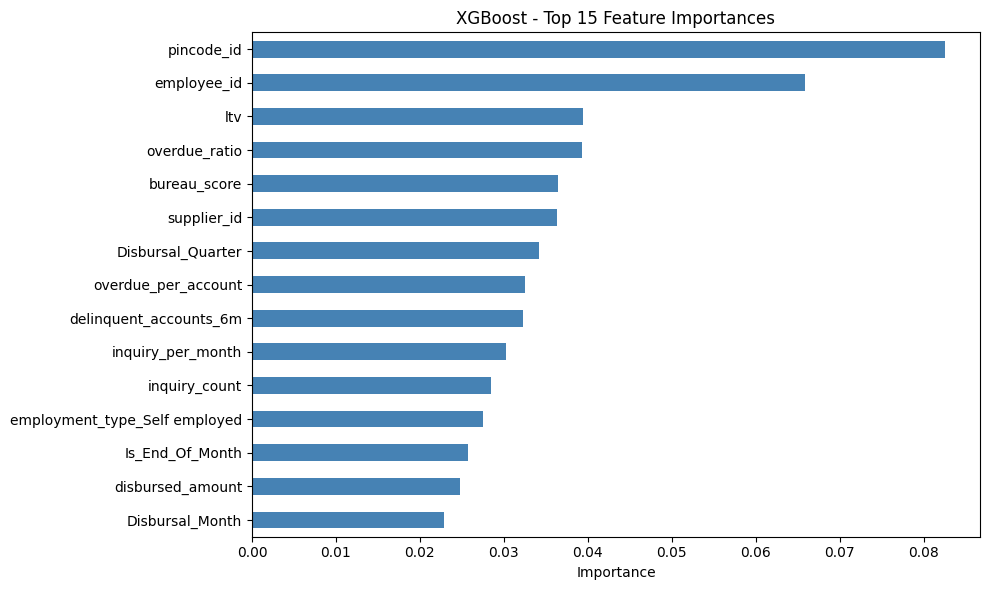

In [61]:
# Extract and display feature importances from the tuned model
if hasattr(final_model, 'feature_importances_'):
    importances = pd.Series(final_model.feature_importances_, index=X_ft_enc.columns)
    top_features = importances.sort_values(ascending=False).head(15)
    
    plt.figure(figsize=(10, 6))
    top_features.plot(kind='barh', color='steelblue')
    plt.xlabel('Importance')
    plt.title(f'{best_name} - Top 15 Feature Importances')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('../charts/13_feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()

## 15. Export Pipeline

In [65]:
# Bundle everything needed for inference into a single dict
pipeline = {
    'model_name': best_name,
    'best_params': best_params,
    'target_encoder': te_final,
    'calibrated_model': final_calibrator,
    'cat_cols': cat_cols,
    'skewed_cols': skewed_cols,
    'feature_columns': list(X_ft_enc.columns),
    'optimal_f2_threshold': tuned_results[best_name]['holdout_f2_thresh'],
    'metrics': {
        'holdout_pr_auc': tuned_results[best_name]['holdout_pr_auc'],
        'holdout_roc_auc': tuned_results[best_name]['holdout_roc_auc'],
        'holdout_f2': tuned_results[best_name]['holdout_f2'],
    }
}

# Save directly to Kaggle's writable working directory
pickle_path = '/kaggle/working/loan_default_pipeline.pkl'
with open(pickle_path, 'wb') as f:
    pickle.dump(pipeline, f)

print(f"Pipeline saved to {pickle_path}")
print(f"Contents: TargetEncoder + {best_name} (tuned) + Isotonic Calibrator")
print(f"File size: {os.path.getsize(pickle_path) / (1024*1024):.1f} MB")


Pipeline saved to /kaggle/working/loan_default_pipeline.pkl
Contents: TargetEncoder + XGBoost (tuned) + Isotonic Calibrator
File size: 2.6 MB


### 15.1 Verify Pickle Load

In [66]:
# Sanity check: load the pickle from Kaggle's working directory and verify
with open('/kaggle/working/loan_default_pipeline.pkl', 'rb') as f:
    loaded = pickle.load(f)

print(f"Model: {loaded['model_name']}")
print(f"Features expected: {len(loaded['feature_columns'])}")
print(f"Optimal F2 threshold: {loaded['optimal_f2_threshold']:.2f}")
print("Saved metrics:")
for k, v in loaded['metrics'].items():
    print(f"  {k}: {v:.4f}")


Model: XGBoost
Features expected: 43
Optimal F2 threshold: 0.23
Saved metrics:
  holdout_pr_auc: 0.3465
  holdout_roc_auc: 0.6617
  holdout_f2: 0.5951
